<a href="https://colab.research.google.com/github/ZAZW27/FakeSound-ML/blob/main/FakeSound.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# INITIALIZE SUPPORTED PYTHON VERSION

### Importing drive to colab

In [ ]:
import os, sys
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


### Core Environment & PyTorch Setup
Setting up the custom Python 3.10 base here to avoid Colab's default environment conflicts. Looping through the core installations (PyTorch, Fairseq, librosa) using subprocess so if a specific wheel fails to build, the cell outputs the exact command and error code.

In [ ]:
import subprocess

cmds = [
    "add-apt-repository ppa:deadsnakes/ppa -y",
    "apt-get install -y python3.10 python3.10-venv python3.10-dev python3.10-distutils",
    "curl -sS https://bootstrap.pypa.io/get-pip.py | /usr/bin/python3.10",
    "/usr/bin/python3.10 -m pip install torch==2.11.0 torchaudio==2.11.0 torchvision==0.26.0 --index-url https://download.pytorch.org/whl/cu128",
    "/usr/bin/python3.10 -m pip install git+https://github.com/pytorch/fairseq@3d262bb25690e4eb2e7d3c1309b1e9c406ca4b99",
    "/usr/bin/python3.10 -m pip install librosa==0.11.0 timm==1.0.27 transformers==5.8.0 hydra-core==1.0.7 omegaconf==2.0.6 sacrebleu==2.6.0 tensorboardX==2.6.5 datasets==4.8.5 soundfile numba scipy scikit-learn tqdm pyyaml",
]

for cmd in cmds:
    print(f"Running: {cmd}")
    result = subprocess.run(cmd, shell=True, capture_output=False)
    print(f"Done: returncode={result.returncode}\n")

Running: add-apt-repository ppa:deadsnakes/ppa -y
Done: returncode=0

Running: apt-get install -y python3.10 python3.10-venv python3.10-dev python3.10-distutils
Done: returncode=0

Running: curl -sS https://bootstrap.pypa.io/get-pip.py | /usr/bin/python3.10
Done: returncode=0

Running: /usr/bin/python3.10 -m pip install torch==2.11.0 torchaudio==2.11.0 torchvision==0.26.0 --index-url https://download.pytorch.org/whl/cu128
Done: returncode=0

Running: /usr/bin/python3.10 -m pip install git+https://github.com/pytorch/fairseq@3d262bb25690e4eb2e7d3c1309b1e9c406ca4b99
Done: returncode=1

Running: /usr/bin/python3.10 -m pip install librosa==0.11.0 timm==1.0.27 transformers==5.8.0 hydra-core==1.0.7 omegaconf==2.0.6 sacrebleu==2.6.0 tensorboardX==2.6.5 datasets==4.8.5 soundfile numba scipy scikit-learn tqdm pyyaml
Done: returncode=1



### Audio Evaluation Libraries Patch Installation

In [ ]:
import subprocess

result = subprocess.run(
    "/usr/bin/python3.10 -m pip install librosa==0.11.0 timm==1.0.27 transformers==5.8.0 hydra-core==1.1.2 omegaconf==2.1.2 sacrebleu==2.6.0 tensorboardX==2.6.5 datasets==4.8.5 soundfile numba scipy scikit-learn tqdm pyyaml sed_eval dcase_util psds_eval bitarray h5py",
    shell=True,
    capture_output=True,
    text=True
)
print(result.stdout[-3000:])
print(result.stderr[-3000:])

873a003e835a5dfb93c924d9b7a010f058883a506fc9ca913d30ad
  Stored in directory: /root/.cache/pip/wheels/55/33/01/ff8f027eb9a938cd294b41c33e502e3deceb60ec394183769d
Successfully built antlr4-python3-runtime sed_eval dcase_util
  Attempting uninstall: pyparsing
    Found existing installation: pyparsing 2.4.7
    Uninstalling pyparsing-2.4.7:
      Successfully uninstalled pyparsing-2.4.7
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2026.4.0
    Uninstalling fsspec-2026.4.0:
      Successfully uninstalled fsspec-2026.4.0





### Env path clean up & validate py version

In [ ]:
import os
os.environ['PATH'] = ':'.join([p for p in os.environ['PATH'].split(':') if 'miniconda' not in p])
!which python3.10

/usr/bin/python3.10


# MODELS EXECUTION
Executes the train_test.py script for the EAT Detection model via a dedicated subprocess. Appends the model directory to PYTHONPATH to resolve internal imports and routes standard output/error for captured logging.

### Run EAT Model Detection

In [ ]:
import subprocess, os

env = os.environ.copy()
env['MPLBACKEND'] = 'Agg'
env['PYTHONPATH'] = '/content/drive/MyDrive/ML/FakeSound/models/EAT/EAT:' + env.get('PYTHONPATH', '')

process = subprocess.Popen(
    [ '/usr/bin/python3.10', 'train_test.py',
      '-f', '/content/drive/MyDrive/ML/FakeSound/deepfake_data/metadata/train.json',
      '-m', 'EAT_Detection',
      '-lr', '1e-4',
      '-b', '64',
      '-e', '40',
    ],
    cwd='/content/drive/MyDrive/ML/FakeSound',
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

for line in process.stdout:
    print(line, end='')

process.wait()
print("Return code:", process.returncode)

/usr/local/lib/python3.10/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
2026-06-14 16:31:38 | INFO | EAT.models.EAT_pretraining | making target model
/content/drive/MyDrive/ML/FakeSound/models/EAT/EAT/models/EAT_pretraining.py:383: FutureWarning: Positional args are being deprecated, use kwargs instead. Refer to https://pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.state_dict for details.
  state = super().state_dict(destination, prefix, keep_vars)
Namespace(train_file='/content/drive/MyDrive/ML/FakeSound/deepfake_data/metadata/train.json', batch_size=64, learning_rate=0.0001, num_epochs=40, output_dir=None, model_class='EAT_Detection', multi_task=False, multi_task_ratio=0.1, duration=10, time_resolution=0.02, sample_rate=16000, num_examples=-1, seed=0)
  Loaded 2

### Run WavLM Model Detection

In [ ]:
import subprocess, os

env = os.environ.copy()
env['MPLBACKEND'] = 'Agg'
env['PYTHONPATH'] = '/content/drive/MyDrive/ML/FakeSound/models/WavLM:' + env.get('PYTHONPATH', '')

process = subprocess.Popen(
    [ '/usr/bin/python3.10', 'train_test.py',
      '-f', '/content/drive/MyDrive/ML/FakeSound/deepfake_data/metadata/train.json',
      '-m', 'WavLM_Detection',
      '-lr', '1e-4',
      '-b', '64',
      '-e', '40',
     ],
    cwd='/content/drive/MyDrive/ML/FakeSound',
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

for line in process.stdout:
    print(line, end='')

process.wait()
print("Return code:", process.returncode)

/usr/local/lib/python3.10/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Namespace(train_file='/content/drive/MyDrive/ML/FakeSound/deepfake_data/metadata/train.json', batch_size=64, learning_rate=0.0001, num_epochs=40, output_dir=None, model_class='WavLM_Detection', multi_task=False, multi_task_ratio=0.1, duration=10, time_resolution=0.02, sample_rate=16000, num_examples=-1, seed=0)
  Loaded 2085 valid samples (skipped 1081 missing files)
Num instances in train: 2085
Optimizing backbone parameters.
Num trainable parameters: 9945089
***** Running training *****
  Num examples = 2085
  Num Epochs = 40
  Instantaneous batch size per device = 64
  Total optimization steps = 1320

100%|██████████| 1320/1320 [2:04:17<00:00,  5.65s/it]
train epoch 0 begin!
train epoch 0 finish!
{'epoch': 0, 'step': 33, 'train_loss': 0.6671, 'best_epoch': 

# Inference test


Running inference: WavLM
/usr/local/lib/python3.10/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
  Loaded 46 valid samples (skipped 46 missing files)

  Test set: easy  (46 samples)

0it [00:00, ?it/s]
1it [00:12, 12.39s/it]
2it [00:24, 12.31s/it]
3it [00:36, 11.92s/it]
3it [00:36, 12.03s/it]

  [WARNING] Only one class detected in y_true. EER set to 0.0.

  Accuracy  : 0.9783
  Precision : 1.0000
  Recall    : 0.9783
  F1        : 0.9890
  EER       : 0.0000
  TP=45  TN=0  FP=0  FN=1

  Segment-based metrics:
  F1 @ 1s    : 0.7172
  F1 @ 0.02s : 0.6837
  F1 @ 0.01s : 0.6840
  Loaded 135 valid samples (skipped 135 missing files)

  Test set: hard  (135 samples)

0it [00:00, ?it/s]
1it [00:12, 12.80s/it]
2it [00:24, 12.40s/it]
3it [00:36, 12.13s/it]
4it [00:50, 12.73s/it]
5it [01:03, 12.71s/it]
6it [01:15, 12.70s/it]
7it [01:32, 1

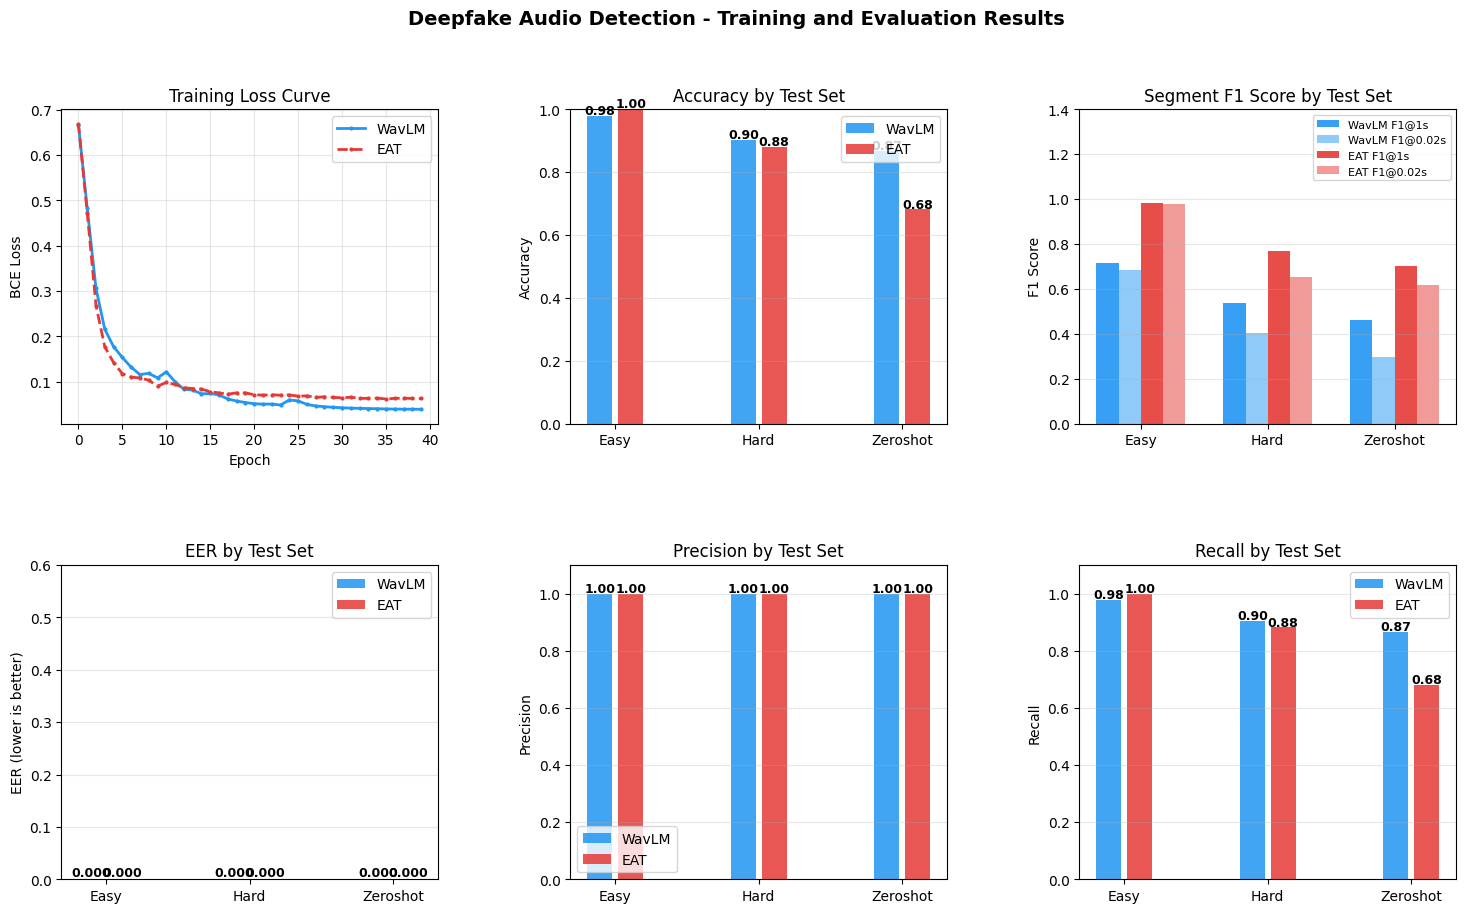


Chart saved: /content/drive/MyDrive/ML/FakeSound/combined_evaluation.png


In [ ]:
import subprocess, os, re, json
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

env = os.environ.copy()
env['MPLBACKEND'] = 'Agg'

models = {
    "WavLM": {
        "pythonpath": '/content/drive/MyDrive/ML/FakeSound/models/WavLM',
        "exp_path": '/content/drive/MyDrive/ML/FakeSound/ckpts/WavLM_Detection/acc',
    },
    "EAT": {
        "pythonpath": '/content/drive/MyDrive/ML/FakeSound/models/EAT/EAT',
        "exp_path": '/content/drive/MyDrive/ML/FakeSound/ckpts/EAT_Detection/acc',
    },
}

COLORS = {"WavLM": "#2196F3", "EAT": "#E53935"}
STYLES = {"WavLM": "-", "EAT": "--"}

def parse_output(output_text, model_name):
    results = {}
    current_set = None
    for line in output_text.splitlines():
        m = re.search(r'Test set:\s*(\w+)', line)
        if m:
            current_set = m.group(1)
            results[current_set] = {}
        if current_set is None:
            continue
        for key, pattern in [
            ('acc', r'Accuracy\s*:\s*([\d.]+)'),
            ('precision', r'Precision\s*:\s*([\d.]+)'),
            ('recall', r'Recall\s*:\s*([\d.]+)'),
            ('f1', r'F1\s*:\s*([\d.]+)'),
            ('eer', r'EER\s*:\s*([\d.]+)'),
            ('f1_1s', r'F1 @ 1s\s*:\s*([\d.]+)'),
            ('f1_002s', r'F1 @ 0\.02s\s*:\s*([\d.]+)'),
        ]:
            m2 = re.search(pattern, line)
            if m2:
                results[current_set][key] = float(m2.group(1))
    return results

def load_losses(exp_path):
    path = os.path.join(exp_path, "summary.jsonl")
    losses = []
    try:
        with open(path) as f:
            for line in f:
                line = line.strip()
                if line:
                    d = json.loads(line)
                    if 'train_loss' in d:
                        losses.append(d['train_loss'])
    except FileNotFoundError:
        pass
    return losses

# Define the custom test files here
custom_test_files = {
    "easy": "/content/drive/MyDrive/ML/FakeSound/deepfake_data/metadata/easy.json",
    "hard": "/content/drive/MyDrive/ML/FakeSound/deepfake_data/metadata/hard.json",
    "zeroshot": "/content/drive/MyDrive/ML/FakeSound/deepfake_data/metadata/zeroshot.json"
}

# Run inference for each models
all_results = {}
loss_data   = {}

for model_name, cfg in models.items():
    print(f"\n{'='*50}")
    print(f"Running inference: {model_name}")
    print(f"{'='*50}")

    run_env = env.copy()
    run_env['PYTHONPATH'] = cfg['pythonpath'] + ':' + run_env.get('PYTHONPATH', '')

    process = subprocess.Popen(
        ['/usr/bin/python3.10', 'inference_test.py',
         '--exp_path', cfg['exp_path'],
         '--threshold', '0.3',
         '-f', json.dumps(custom_test_files)], # <--- Injected here
        cwd='/content/drive/MyDrive/ML/FakeSound',
        env=run_env,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True
    )

    output_lines = []
    for line in process.stdout:
        print(line, end='')
        output_lines.append(line)
    process.wait()
    print(f"\n{model_name} Return code: {process.returncode}")

    if process.returncode == 0:
        parsed = parse_output(''.join(output_lines), model_name)
        if parsed:
            all_results[model_name] = parsed

    losses = load_losses(cfg['exp_path'])
    if losses:
        loss_data[model_name] = losses

# Plotting
if not all_results:
    print("Tidak ada hasil inference, skip chart.")
else:
    test_sets   = sorted({ts for r in all_results.values() for ts in r.keys()})
    model_names = list(all_results.keys())

    fig = plt.figure(figsize=(18, 10))
    fig.suptitle("Deepfake Audio Detection - Training and Evaluation Results", fontsize=14, fontweight='bold')
    gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

    # Loss Curve overlapping
    ax1 = fig.add_subplot(gs[0, 0])
    for name, losses in loss_data.items():
        ax1.plot(losses, label=name, color=COLORS.get(name, "#333"),
                 linestyle=STYLES.get(name, "-"), linewidth=2, marker='o', markersize=2)
    ax1.set_title("Training Loss Curve")
    ax1.set_xlabel("Epoch"); ax1.set_ylabel("BCE Loss")
    ax1.legend(); ax1.grid(True, alpha=0.3)

    # Accuracy grouped bar
    ax2   = fig.add_subplot(gs[0, 1])
    x     = np.arange(len(test_sets))
    n_m   = len(model_names)
    width = 0.35 / max(n_m, 1)
    for i, name in enumerate(model_names):
        accs   = [all_results[name].get(ts, {}).get('acc', 0) for ts in test_sets]
        offset = (i - n_m / 2 + 0.5) * (width + 0.04)
        bars   = ax2.bar(x + offset, accs, width, label=name, color=COLORS.get(name, "#333"), alpha=0.85)
        for b, v in zip(bars, accs):
            ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 0.005,
                     f"{v:.2f}", ha='center', fontsize=9, fontweight='bold')
    ax2.set_title("Accuracy by Test Set")
    ax2.set_xticks(x); ax2.set_xticklabels([s.capitalize() for s in test_sets])
    ax2.set_ylim(0, 1); ax2.set_ylabel("Accuracy")
    ax2.legend(); ax2.grid(True, axis='y', alpha=0.3)

    # Segment F1
    ax3      = fig.add_subplot(gs[0, 2])
    n_series = n_m * 2
    total_w  = 0.7
    bar_w    = total_w / n_series
    offsets  = np.linspace(-total_w/2 + bar_w/2, total_w/2 - bar_w/2, n_series)
    idx = 0
    for name in model_names:
        c      = COLORS.get(name, "#333")
        f1_1s  = [all_results[name].get(ts, {}).get('f1_1s',   0) for ts in test_sets]
        f1_002 = [all_results[name].get(ts, {}).get('f1_002s', 0) for ts in test_sets]
        ax3.bar(x + offsets[idx],   f1_1s,  bar_w, label=f"{name} F1@1s",    color=c, alpha=0.9)
        ax3.bar(x + offsets[idx+1], f1_002, bar_w, label=f"{name} F1@0.02s", color=c, alpha=0.5)
        idx += 2
    ax3.set_title("Segment F1 Score by Test Set")
    ax3.set_xticks(x); ax3.set_xticklabels([s.capitalize() for s in test_sets])
    ax3.set_ylim(0, 1.4); ax3.set_ylabel("F1 Score")
    ax3.legend(fontsize=8); ax3.grid(True, axis='y', alpha=0.3)

    # EER
    ax4 = fig.add_subplot(gs[1, 0])
    for i, name in enumerate(model_names):
        eers   = [all_results[name].get(ts, {}).get('eer', 0) for ts in test_sets]
        offset = (i - n_m / 2 + 0.5) * (width + 0.04)
        bars   = ax4.bar(x + offset, eers, width, label=name, color=COLORS.get(name, "#333"), alpha=0.85)
        for b, v in zip(bars, eers):
            ax4.text(b.get_x() + b.get_width()/2, b.get_height() + 0.005,
                     f"{v:.3f}", ha='center', fontsize=9, fontweight='bold')
    ax4.set_title("EER by Test Set")
    ax4.set_xticks(x); ax4.set_xticklabels([s.capitalize() for s in test_sets])
    ax4.set_ylim(0, 0.6); ax4.set_ylabel("EER (lower is better)")
    ax4.legend(); ax4.grid(True, axis='y', alpha=0.3)

    # Precision & Recall
    ax5 = fig.add_subplot(gs[1, 1])
    ax6 = fig.add_subplot(gs[1, 2])
    for i, name in enumerate(model_names):
        precs  = [all_results[name].get(ts, {}).get('precision', 0) for ts in test_sets]
        recs   = [all_results[name].get(ts, {}).get('recall',    0) for ts in test_sets]
        offset = (i - n_m / 2 + 0.5) * (width + 0.04)
        bars_p = ax5.bar(x + offset, precs, width, label=name, color=COLORS.get(name, "#333"), alpha=0.85)
        bars_r = ax6.bar(x + offset, recs,  width, label=name, color=COLORS.get(name, "#333"), alpha=0.85)
        for b, v in zip(bars_p, precs):
            ax5.text(b.get_x() + b.get_width()/2, b.get_height() + 0.005,
                     f"{v:.2f}", ha='center', fontsize=9, fontweight='bold')
        for b, v in zip(bars_r, recs):
            ax6.text(b.get_x() + b.get_width()/2, b.get_height() + 0.005,
                     f"{v:.2f}", ha='center', fontsize=9, fontweight='bold')

    for ax, title, ylabel in [(ax5, "Precision by Test Set", "Precision"),
                               (ax6, "Recall by Test Set",   "Recall")]:
        ax.set_title(title)
        ax.set_xticks(x); ax.set_xticklabels([s.capitalize() for s in test_sets])
        ax.set_ylim(0, 1.1); ax.set_ylabel(ylabel)
        ax.legend(); ax.grid(True, axis='y', alpha=0.3)

    save_path = '/content/drive/MyDrive/ML/FakeSound/combined_evaluation.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"\nChart saved: {save_path}")

# Analyze dataset

In [ ]:
import os
import json

BASE_DIR = "/content/drive/MyDrive/ML/FakeSound/"

splits = {
    "train": os.path.join(BASE_DIR, "deepfake_data/metadata/train.json"),
    # "test_short": os.path.join(BASE_DIR, "deepfake_data-longshort/test_short.json"),
    # "test_long": os.path.join(BASE_DIR, "deepfake_data-longshort/test_long.json")
    "easy": os.path.join(BASE_DIR, "deepfake_data/metadata/easy.json"),
    "hard": os.path.join(BASE_DIR, "deepfake_data/metadata/hard.json"),
    "zeroshot": os.path.join(BASE_DIR, "deepfake_data/metadata/zeroshot.json"),
}

def count_and_report_missing():
    for split_name, json_path in splits.items():
        print(f"\n" + "="*40)
        print(f"SPLIT: {split_name.upper()}")
        print("="*40)

        if not os.path.exists(json_path):
            print(f"Error: JSON metadata not found: {json_path}")
            continue

        with open(json_path, 'r') as f:
            data = json.load(f)

        audios = data.get("audios", [])

        meta_real = 0
        meta_spoof = 0
        phys_real = 0
        phys_spoof = 0

        missing_real_files = []
        missing_spoof_files = []

        for item in audios:
            label = item.get("label")
            json_filepath = item.get("filepath", "")

            phys_path = json_filepath.replace("FakeSound/", BASE_DIR)
            filename = os.path.basename(phys_path)

            exists = os.path.exists(phys_path)

            if label == 0:
                meta_real += 1
                if exists:
                    phys_real += 1
                else:
                    missing_real_files.append(filename)
            elif label == 1:
                meta_spoof += 1
                if exists:
                    phys_spoof += 1
                else:
                    missing_spoof_files.append(filename)

        total_physical = phys_real + phys_spoof
        total_missing = len(missing_real_files) + len(missing_spoof_files)

        print(f"Total entry in Metadata   : {len(audios)}")
        print(f"Total file found in folder: {total_physical}")
        print(f"Total file missing        : {total_missing}")

        print(f"\n--- Exists in folder ---")
        print(f"Bonafide (Real)           : {phys_real} / {meta_real}")
        print(f"Spoofed (Fake)            : {phys_spoof} / {meta_spoof}")

if __name__ == "__main__":
    count_and_report_missing()


SPLIT: TRAIN
Total entry in Metadata   : 3166
Total file found in folder: 2085
Total file missing        : 1081

--- Exists in folder ---
Bonafide (Real)           : 502 / 1583
Spoofed (Fake)            : 1583 / 1583

SPLIT: EASY
Total entry in Metadata   : 92
Total file found in folder: 46
Total file missing        : 46

--- Exists in folder ---
Bonafide (Real)           : 0 / 46
Spoofed (Fake)            : 46 / 46

SPLIT: HARD
Total entry in Metadata   : 270
Total file found in folder: 135
Total file missing        : 135

--- Exists in folder ---
Bonafide (Real)           : 0 / 135
Spoofed (Fake)            : 135 / 135

SPLIT: ZEROSHOT
Total entry in Metadata   : 270
Total file found in folder: 135
Total file missing        : 135

--- Exists in folder ---
Bonafide (Real)           : 0 / 135
Spoofed (Fake)            : 135 / 135


# Dataset in Matplot


=== Processing train ===
Meta: 3166 | Found: 2085 | Missing: 1081
Real: 1583 | Fake: 1583
Real found: 502 | Fake found: 1583
Real missing: 1081 | Fake missing: 0

=== Processing test_short ===
Meta: 251 | Found: 251 | Missing: 0
Real: 125 | Fake: 126
Real found: 125 | Fake found: 126
Real missing: 0 | Fake missing: 0

=== Processing test_long ===
Meta: 244 | Found: 244 | Missing: 0
Real: 122 | Fake: 122
Real found: 122 | Fake found: 122
Real missing: 0 | Fake missing: 0


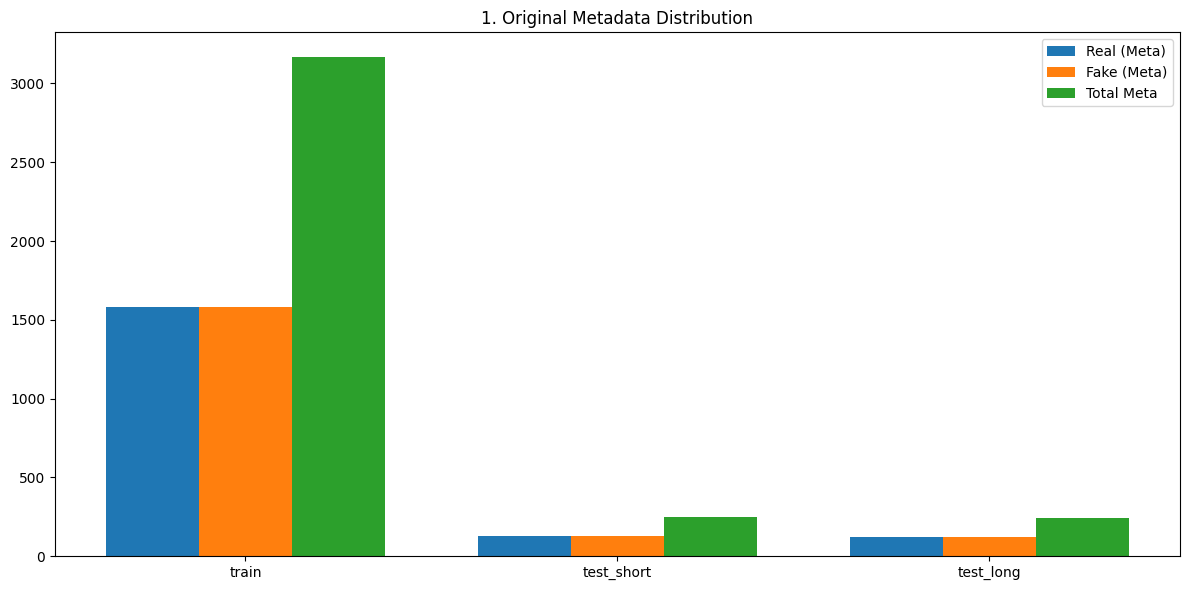

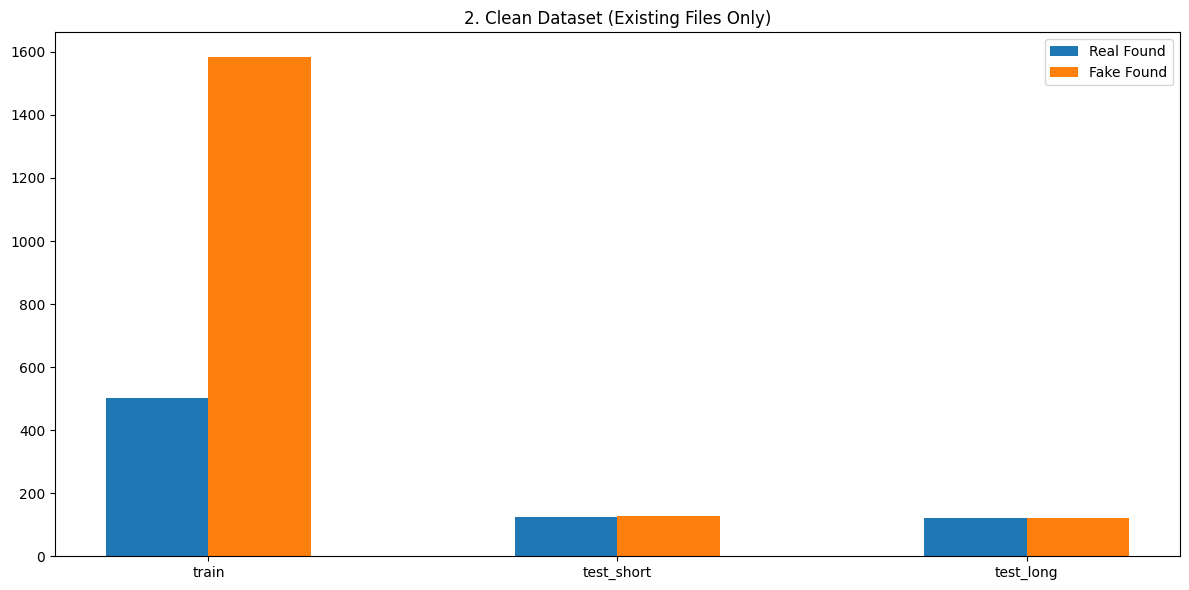

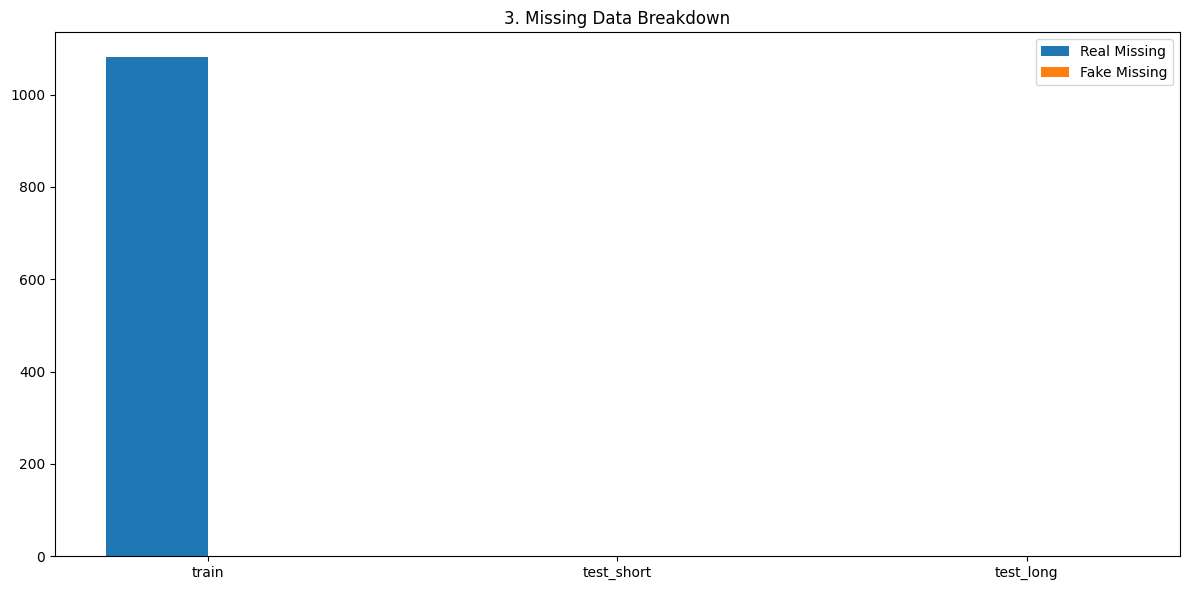

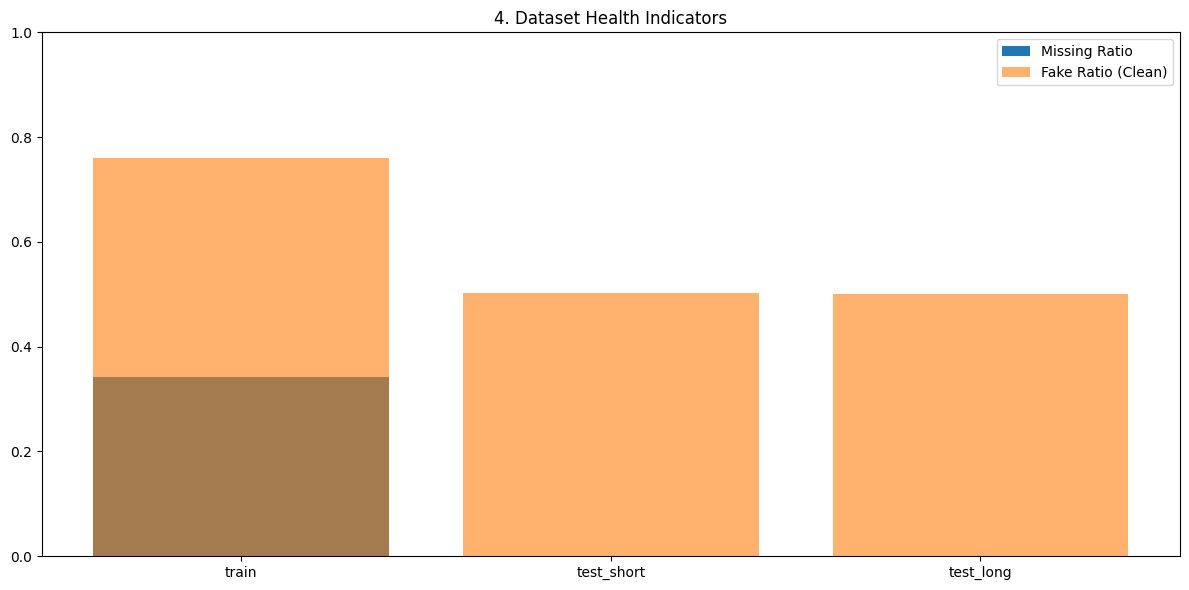

In [ ]:
import os
import json
import matplotlib.pyplot as plt
import numpy as np

BASE_DIR = "/content/drive/MyDrive/ML/FakeSound/"

splits = {
    "train": os.path.join(BASE_DIR, "deepfake_data/metadata/train.json"),
    "test_short": os.path.join(BASE_DIR, "deepfake_data-longshort/test_short.json"),
    "test_long": os.path.join(BASE_DIR, "deepfake_data-longshort/test_long.json")
}

names = []

# =====================
# ORIGINAL METADATA
# =====================
meta_real = []
meta_fake = []
meta_total = []

# =====================
# FILE SYSTEM STATUS
# =====================
found_total = []
missing_total = []

real_found = []
fake_found = []

real_missing = []
fake_missing = []

# =====================
# RATIOS
# =====================
fake_ratio_clean = []
missing_ratio = []

# =====================
# MAIN LOOP
# =====================
for split_name, json_path in splits.items():
    names.append(split_name)

    print(f"\n=== Processing {split_name} ===")

    if not os.path.exists(json_path):
        print("JSON not found!")

        meta_real.append(0)
        meta_fake.append(0)
        meta_total.append(0)

        found_total.append(0)
        missing_total.append(0)

        real_found.append(0)
        fake_found.append(0)

        real_missing.append(0)
        fake_missing.append(0)

        fake_ratio_clean.append(0)
        missing_ratio.append(0)
        continue

    with open(json_path, "r") as f:
        data = json.load(f)

    audios = data.get("audios", [])

    mr = mf = 0

    rf = ff = 0
    rm = fm = 0

    for item in audios:
        label = item.get("label")
        path = item.get("filepath", "").replace("FakeSound/", BASE_DIR)

        if label == 0:
            mr += 1
        else:
            mf += 1

        exists = os.path.exists(path)

        if exists:
            if label == 0:
                rf += 1
            else:
                ff += 1
        else:
            if label == 0:
                rm += 1
            else:
                fm += 1

    total_meta = mr + mf
    total_found = rf + ff
    total_missing = rm + fm

    meta_real.append(mr)
    meta_fake.append(mf)
    meta_total.append(total_meta)

    found_total.append(total_found)
    missing_total.append(total_missing)

    real_found.append(rf)
    fake_found.append(ff)

    real_missing.append(rm)
    fake_missing.append(fm)

    fake_ratio_clean.append(ff / (total_found + 1e-9))
    missing_ratio.append(total_missing / (total_meta + 1e-9))

    print(f"Meta: {total_meta} | Found: {total_found} | Missing: {total_missing}")
    print(f"Real: {mr} | Fake: {mf}")
    print(f"Real found: {rf} | Fake found: {ff}")
    print(f"Real missing: {rm} | Fake missing: {fm}")

# =====================
# PLOTTING DASHBOARD
# =====================
x = np.arange(len(names))
width = 0.25

# =====================
# 1. META DISTRIBUTION
# =====================
plt.figure(figsize=(12, 6))
plt.bar(x - width, meta_real, width, label="Real (Meta)")
plt.bar(x, meta_fake, width, label="Fake (Meta)")
plt.bar(x + width, meta_total, width, label="Total Meta")
plt.xticks(x, names)
plt.title("1. Original Metadata Distribution")
plt.legend()
plt.tight_layout()
plt.show()

# =====================
# 2. CLEAN DATASET
# =====================
plt.figure(figsize=(12, 6))
plt.bar(x - width/2, real_found, width, label="Real Found")
plt.bar(x + width/2, fake_found, width, label="Fake Found")
plt.xticks(x, names)
plt.title("2. Clean Dataset (Existing Files Only)")
plt.legend()
plt.tight_layout()
plt.show()

# =====================
# 3. MISSING DATA
# =====================
plt.figure(figsize=(12, 6))
plt.bar(x - width/2, real_missing, width, label="Real Missing")
plt.bar(x + width/2, fake_missing, width, label="Fake Missing")
plt.xticks(x, names)
plt.title("3. Missing Data Breakdown")
plt.legend()
plt.tight_layout()
plt.show()

# =====================
# 4. DATASET HEALTH INDICATORS
# =====================
plt.figure(figsize=(12, 6))
plt.bar(x, missing_ratio, label="Missing Ratio")
plt.bar(x, fake_ratio_clean, alpha=0.6, label="Fake Ratio (Clean)")
plt.xticks(x, names)
plt.ylim(0, 1)
plt.title("4. Dataset Health Indicators")
plt.legend()
plt.tight_layout()
plt.show()